<a href="https://colab.research.google.com/github/Decoding-Data-Science/airesidency/blob/main/MC05_Live_Lab_Generation_vs_Reasoning_v2_1bf97621_ipynb_txt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MC05 Live Lab - Generation vs Reasoning Controls
**AI Residency - Cohort 12 - 14 November 2026**

**Goal:** see, with your own runs, how generation controls (temperature, top-p, penalties, token limits) differ from reasoning controls (model choice, reasoning effort) - and compare **token usage and response time** fairly.

> Main message: generation settings change how the model **speaks**; reasoning settings change how much the model **thinks**. Neither guarantees a correct answer - always evaluate the output.

## Setup (30 seconds)
1. In the Colab left sidebar, click the **key icon (Secrets)**.
2. Add a secret named **`openai`** (this notebook also accepts `OPENAI_API_KEY`).
3. Paste your OpenAI API key and enable notebook access.

Never paste a key into a code cell. No key is stored in this notebook.

In [1]:
!pip -q install --upgrade openai pandas matplotlib
import time
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
# Load the API key from Colab Secrets - never hardcode it.
import os
key = None
try:
    from google.colab import userdata
    for name in ("openai", "OPENAI_API_KEY"):
        try:
            v = userdata.get(name)
            if v:
                key = v
                break
        except Exception:
            continue  # secret with this name does not exist - try the next one
except Exception:
    pass
if not key:
    key = os.environ.get("OPENAI_API_KEY")
assert key, "Add your OpenAI key in Colab Secrets as 'openai' (or OPENAI_API_KEY) and enable notebook access."
os.environ["OPENAI_API_KEY"] = key
client = OpenAI()
print("OpenAI client ready.")

OpenAI client ready.


## 1. Choose the two models
One **generation** model for style experiments, one **reasoning** model for thinking experiments.

Defaults below are current as of 14 Nov 2026 (OpenAI docs): `gpt-4.1-mini` for fast generation, `gpt-5.6-luna` as the lowest-cost reasoning model (`gpt-5.6-terra` is the next step up; `gpt-6-astra` is the flagship). **If your account does not have a model, change the name here** - the optional cell below lists what your account can see.

Official sources for these choices:
- Model overview: https://developers.openai.com/api/docs/models
- Reasoning guide (effort values, reasoning tokens): https://developers.openai.com/api/docs/guides/reasoning
- GPT-6 Astra model card (efforts low/medium/high/xhigh/max): https://developers.openai.com/api/docs/models/gpt-6-astra
- Chat Completions reference (reasoning_effort, parameter support by model): https://developers.openai.com/api/reference/resources/chat

In [3]:
GENERATION_MODEL = "gpt-4.1-mini"   # fast generation model for temperature / top-p / penalty demos
REASONING_MODEL  = "gpt-5.6-luna"   # low-cost reasoning model for effort demos (alternatives: gpt-5.6-terra, gpt-6-astra)
print("Generation model:", GENERATION_MODEL)
print("Reasoning model:", REASONING_MODEL)

Generation model: gpt-4.1-mini
Reasoning model: gpt-5.6-luna


In [ ]:
# Optional: check which models your key can access (uncomment to run).
# for m in client.models.list():
#     print(m.id)

## 2. Two helpers
- `run_generation(...)` uses **Chat Completions** with temperature, top-p, penalties and a token ceiling.
- `run_reasoning(...)` uses the **Responses API** with `reasoning={"effort": ...}`.

Both return the answer text **plus token usage and elapsed seconds**, so every experiment reports cost and speed. If the API rejects a setting, the error message is shown instead of crashing - that is part of the lesson.

In [4]:
def run_generation(prompt, model=GENERATION_MODEL, temperature=0.7, top_p=None,
                   frequency_penalty=None, presence_penalty=None, max_completion_tokens=300):
    params = {"model": model,
              "messages": [{"role": "user", "content": prompt}],
              "temperature": temperature,
              "max_completion_tokens": max_completion_tokens}
    if top_p is not None: params["top_p"] = top_p
    if frequency_penalty is not None: params["frequency_penalty"] = frequency_penalty
    if presence_penalty is not None: params["presence_penalty"] = presence_penalty
    t0 = time.time()
    try:
        r = client.chat.completions.create(**params)
        dt = time.time() - t0
        u = r.usage
        return {"text": r.choices[0].message.content, "seconds": round(dt, 1),
                "prompt_tokens": u.prompt_tokens, "completion_tokens": u.completion_tokens,
                "total_tokens": u.total_tokens, "error": None}
    except Exception as e:
        return {"text": "", "seconds": round(time.time() - t0, 1), "prompt_tokens": 0,
                "completion_tokens": 0, "total_tokens": 0, "error": str(e)[:400]}

def run_reasoning(prompt, model=REASONING_MODEL, effort="medium", max_output_tokens=2000,
                  extra_params=None):
    params = {"model": model, "input": prompt,
              "reasoning": {"effort": effort}, "max_output_tokens": max_output_tokens}
    if extra_params: params.update(extra_params)
    t0 = time.time()
    try:
        r = client.responses.create(**params)
        dt = time.time() - t0
        u = r.usage
        reasoning_tokens = getattr(getattr(u, "output_tokens_details", None), "reasoning_tokens", None)
        inc = getattr(r, "incomplete_details", None)
        inc_reason = getattr(inc, "reason", None) if inc else None
        return {"text": getattr(r, "output_text", ""), "seconds": round(dt, 1),
                "status": getattr(r, "status", None), "incomplete_reason": inc_reason,
                "output_tokens": u.output_tokens, "reasoning_tokens": reasoning_tokens,
                "total_tokens": u.total_tokens, "error": None}
    except Exception as e:
        return {"text": "", "seconds": round(time.time() - t0, 1), "status": "failed",
                "incomplete_reason": None, "output_tokens": 0,
                "reasoning_tokens": None, "total_tokens": 0, "error": str(e)[:400]}

def show(result, max_chars=700):
    if result["error"]:
        print("API response (error):", result["error"]); return
    print(result["text"][:max_chars])
    print("---")
    print({k: v for k, v in result.items() if k != "text"})

## 3. Demo A - Temperature sweep (generation model)
**Fair test:** same model, same prompt, same token ceiling - only `temperature` changes.

Teaching line: temperature changes the **variety** of wording, not the model's knowledge. Low is not "true" and high is not "smart" - a model can repeat a wrong answer confidently at temperature 0.

In [5]:
prompt = "Write a two-sentence tagline for a Dubai AI meetup."
for temp in [0.2, 0.7, 2]:
    print(f"=== temperature {temp} ===")
    show(run_generation(prompt, temperature=temp, max_completion_tokens=120))
    print()

=== temperature 0.2 ===
Unlock the future of innovation at Dubai AI Meetup, where brilliant minds converge to shape tomorrow’s technology today. Join us to explore cutting-edge AI breakthroughs and connect with the region’s brightest tech enthusiasts.
---
{'seconds': 2.6, 'prompt_tokens': 19, 'completion_tokens': 39, 'total_tokens': 58, 'error': None}

=== temperature 0.7 ===
Connecting innovators and visionaries to shape the future of AI in Dubai.  
Where cutting-edge technology meets the dynamic spirit of the city.
---
{'seconds': 1.6, 'prompt_tokens': 19, 'completion_tokens': 27, 'total_tokens': 46, 'error': None}

=== temperature 2 ===
Dubai AI Meetup: Igniting innovative tech ideas where visionaries converge to shape the future of artificial intelligence.  
Connect, learn, and lead at the forefront of AI in the heart of Dubai’s dynamic tech landscape.
---
{'seconds': 1.6, 'prompt_tokens': 19, 'completion_tokens': 43, 'total_tokens': 62, 'error': None}



## 4. Demo B - Does the reasoning model accept temperature?
Do not assume - **test it**. Many reasoning models reject sampling controls. This cell sends `temperature` to the reasoning model and reports whether the **request** was accepted or failed.

Two cautions:
- A failed request can fail for many reasons (auth, quota, model access, network) - read the actual error message before concluding the parameter was the cause.
- An **accepted** request does not prove the parameter was **applied**. Only the model's docs establish which parameters a given model honours.

In [12]:
# it doesn't accept any temperature other than 1 which is a default, testit yourself
probe = run_reasoning("Name one practical use of AI in logistics.",
                      effort="low", max_output_tokens=300,
                      extra_params={"temperature": 0.5})
if probe["error"]:
    print("The request failed. Inspect the message before blaming the parameter -")
    print("auth, quota, model access and network problems look the same from here.")
    print()
    print(probe["error"])
else:
    print("The request was accepted by the API (accepted does not prove the parameter was applied).")
    show(probe)

The request failed. Inspect the message before blaming the parameter -
auth, quota, model access and network problems look the same from here.

Error code: 400 - Unsupported parameter: 'temperature' is not supported with this model.


In [11]:
#without temperature
probe = run_reasoning("Name one practical use of AI in logistics.",
                      effort="low", max_output_tokens=300
                  )
if probe["error"]:
    print("The request failed. Inspect the message before blaming the parameter -")
    print("auth, quota, model access and network problems look the same from here.")
    print()
    print(probe["error"])
else:
    print("The request was accepted by the API (accepted does not prove the parameter was applied).")
    show(probe)

The request was accepted by the API (accepted does not prove the parameter was applied).
AI can optimize delivery routes in real time, reducing travel time, fuel costs, and delays.
---
{'seconds': 1.9, 'status': 'completed', 'incomplete_reason': None, 'output_tokens': 23, 'reasoning_tokens': 0, 'total_tokens': 38, 'error': None}


## 5. Demo C - Reasoning effort sweep (the fair version)
Same reasoning model, same prompt, same `max_output_tokens` - **only `effort` changes**. (In class we saw a run where reasoning mode, effort AND verbosity all changed together: that compares two configurations, not effort alone.)

Watch three numbers per run: **output tokens**, **reasoning tokens** (the hidden thinking, reported separately by the API), and **seconds**.

Teaching line: more thinking usually means slower and pricier - and still not a guarantee of correctness.

In [13]:
decision_prompt = (
    "A telecom company wants an AI customer-support assistant. They have 50,000 past tickets, "
    "a FAQ website, and a small developer team. Should they start with a prompt-based chatbot, "
    "RAG, fine-tuning, or an agent with tools? Recommend one, with the main trade-off.")

rows = []
for effort in ["low", "medium", "high"]:
    print(f"=== reasoning effort: {effort} ===")
    r = run_reasoning(decision_prompt, effort=effort, max_output_tokens=2000)
    show(r, max_chars=500)
    if r["incomplete_reason"]:
        print(f"NOTE: response status = {r['status']}, incomplete reason = {r['incomplete_reason']} - "
              "a blank or short answer here is the token budget running out, not a successful run.")
    print()
    rows.append({"effort": effort, "status": r["status"], "incomplete_reason": r["incomplete_reason"],
                 "output_tokens": r["output_tokens"], "reasoning_tokens": r["reasoning_tokens"],
                 "total_tokens": r["total_tokens"], "seconds": r["seconds"],
                 "error": (r["error"] or "")[:120]})

df = pd.DataFrame(rows)
ok = df[(df["error"] == "") & (df["status"] == "completed")].copy()
if len(ok) < len(df):
    print("Excluded from the chart (failed or incomplete runs):")
    print(df.loc[df.index.difference(ok.index), ["effort", "status", "incomplete_reason", "error"]].to_string(index=False))
df

=== reasoning effort: low ===
Start with a **RAG-based assistant**: use a strong general-purpose model, retrieve relevant content from the FAQ and carefully selected past tickets, and instruct it to answer only from the retrieved sources or escalate when uncertain.

**Why:**  
- The FAQ provides authoritative, updatable knowledge.  
- The 50,000 tickets can supply real customer phrasing, troubleshooting patterns, and examples.  
- It avoids the high cost and maintenance of fine-tuning.  
- It is safer and simpler than beginn
---
{'seconds': 3.8, 'status': 'completed', 'incomplete_reason': None, 'output_tokens': 263, 'reasoning_tokens': 61, 'total_tokens': 329, 'error': None}

=== reasoning effort: medium ===
**Recommend starting with a RAG-based chatbot** built on the FAQ site and a curated subset of the 50,000 past tickets.

It can retrieve current, company-specific information and cite the relevant FAQ or resolved-ticket examples without the cost and maintenance of fine-tuning. Use a

,effort,status,incomplete_reason,output_tokens,reasoning_tokens,total_tokens,seconds,error
0,low,completed,None,263,61,329,3.8,
1,medium,completed,None,246,76,312,3.7,
2,high,completed,None,258,102,324,4.0,


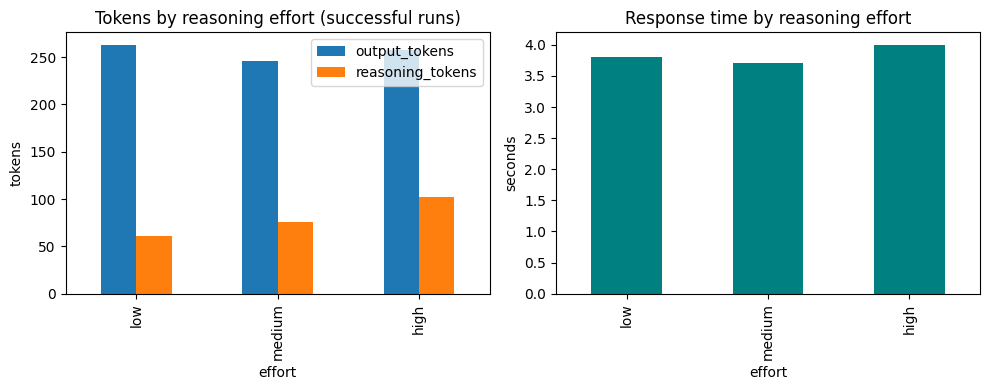

In [14]:
if ok.empty:
    print("No successful runs to chart yet - check the status/error columns above.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ok.plot(x="effort", y=["output_tokens", "reasoning_tokens"], kind="bar", ax=axes[0])
    axes[0].set_title("Tokens by reasoning effort (successful runs)"); axes[0].set_ylabel("tokens")
    ok.plot(x="effort", y="seconds", kind="bar", ax=axes[1], color="teal", legend=False)
    axes[1].set_title("Response time by reasoning effort"); axes[1].set_ylabel("seconds")
    plt.tight_layout(); plt.show()

## 6. How to read the numbers
- **Verbosity vs token ceiling:** asking for more detail is a request; `max_output_tokens` is a **ceiling**, not a target. Raising the ceiling does not by itself make answers longer.
- **Total tokens vs thinking tokens:** a total alone does not tell you how much was hidden reasoning - use the `reasoning_tokens` breakdown, as above.
- **One run is an anecdote:** repeat a comparison before drawing conclusions, and judge answers against criteria (correctness, relevant trade-offs, missing assumptions) - not just length.

## 7. Participant exercises - change ONE thing at a time
1. Re-run Demo A with temperature 0.0 twice. Are the answers identical? What does that tell you?
2. Re-run Demo C with `max_output_tokens=400`. What happens at high effort - and why?
3. Try `effort="xhigh"` if your model supports it (check the model docs). Add the row to the table.
4. Pick a task from your own work and decide first: is this a *generation* problem (wording) or a *reasoning* problem (judgment)? Then choose the model and the control.

## 8. Troubleshooting
- Secret name must be `openai` or `OPENAI_API_KEY`, with notebook access enabled.
- "Model not found" / access error: your key may not have that model - change `GENERATION_MODEL` / `REASONING_MODEL` (cell in section 1).
- A rejected parameter is data, not failure: it tells you that control is not exposed for that model.

> Final takeaway: choose the right model and provide the right context first; then use the lowest reasoning effort that reliably meets the task's needs; tune generation settings last - and evaluate the actual outputs.